# Decision Tree Regression

Original article in [Kaggle](https://www.kaggle.com/code/mcmuralishclint/decision-tree-regression/notebook)

[Car Price Prediction dataset](https://www.kaggle.com/datasets/hashroot97/carpriceprediction)

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load in 

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list the files in the input directory

import os
print(os.listdir("./data"))

# Any results you write to the current directory are saved as output.

['matildas.csv', 'nyc-taxi-train', 'week_1_lesson_4_internet.csv', '.DS_Store', 'countries.csv', 'week_3_WA_Fn-UseC_-HR-Employee-Attrition.csv', 'map_tile_cache', 'week_1_lesson_4_profit.csv', 'week_3_car_price_prediction_data.csv', 'matildas_source.csv', 'nyc-taxi-trip-duration.zip', 'breast-cancer.csv', 'week_2_survey.csv', 'framingham.csv', 'Wine.csv', 'week_3_drug200.csv', 'titanic', 'week_2_fifa19.csv', 'week_3_Social_Network_Ads.csv', 'studentseffort.csv', 'sydney_airbnb.csv', 'week_1_lesson_4_election.csv', 'week_1_lesson_3.csv', 'bread_basket.csv', 'week_1_lesson_4_payslip.csv']


In [2]:
# The variable and functions below allow the correct conversion to LaTeX tables when exporting to PDF with nbconvert.
def correctness_html(value):
    return {
        'Yes': 'color: green; font-weight: bold;',
        'No': 'color: red; font-weight: bold;',
    }.get(value, '')


def correctness_latex(value):
    return {
        'Yes': 'color:{green}; bfseries:;',
        'No': 'color:{red}; bfseries:;',
    }.get(value, '')


def display_table(
        df,
        formats=None,
        latex_formats=None,
        html_style=None,
        latex_style=None,
        style_columns=None,
        hide_index=True,
        fit_to_page=False,
        na_rep=None,
        multipage=None,
):
    r"""
    Display a DataFrame as HTML and LaTeX for notebook viewing and PDF export.

    Formats values without modifying the DataFrame. The LaTeX version includes
    alternating row shading, bold headers, and escaped row and column labels.

    Parameters
    ----------
    df : pandas.DataFrame
        Table to display.
    formats : dict, optional
        Column names mapped to format strings or formatting functions.
        Used for both outputs unless overridden by latex_formats.
    latex_formats : dict, optional
        Formatting overrides for LaTeX output. Formatters that generate special
        characters must escape them, for example '%' as r'\%'.
    html_style : callable, optional
        Function receiving a cell value and returning a CSS style string.
        Return an empty string to leave the cell unchanged.
    latex_style : callable, optional
        Function receiving a cell value and returning a pandas LaTeX style
        string, such as 'color:{green}; bfseries:;'.
    style_columns : list of str, optional
        Columns to which the styling functions apply. If None, apply them
        to all data cells. Callbacks receive original, unformatted values.
    hide_index : bool, default True
        Hide row indexes in both output formats.
    fit_to_page : bool, default False
        Shrink the LaTeX table if it exceeds the PDF text width.
        Does not affect the HTML display.
    na_rep : str or None, default None
        Text displayed for missing values. If None, use the default rendering
        without a custom replacement. Does not modify the underlying data.

    multipage : bool or None, default None
        Use a LaTeX longtable with repeated headers and page breaks.
        None enables this unless fit_to_page=True. Explicitly combining
        multipage=True and fit_to_page=True raises ValueError.

    Returns
    -------
    None
        Displays HTML and LaTeX representations through IPython.display.

    Notes
    -----
    The PDF template must load xcolor and colortbl for LaTeX styling,
    longtable for multipage tables, and adjustbox when fit_to_page=True.
    Rerun and save the cell outputs before exporting without execution.
    """
    if multipage is None:
        multipage = not fit_to_page
    if multipage and fit_to_page:
        raise ValueError('Multipage tables cannot use fit_to_page=True; disable resizing.')

    formats = formats or {}
    pdf_formats = {**formats, **(latex_formats or {})}

    html = df.style.format(formats, na_rep=na_rep, escape='html')

    if hide_index:
        # There is a pandas LaTeX styling bug when the index is hidden.
        latex = (
            df.style
            .format(pdf_formats, na_rep=na_rep, escape='latex')
            .format_index(escape='latex', axis=0)
            .format_index(
                lambda value: r"\textbf{" + _tex(value) + "}",
                axis=1,
            )
        )
    else:
        latex = (
            df.style
            .format(pdf_formats, na_rep=na_rep, escape='latex')
            .format_index(escape='latex', axis=0)
            .format_index(escape='latex', axis=1)
        )

    if hide_index:
        html = html.hide(axis='index')
        latex = latex.hide(axis='index')

    # Apply LaTeX row shading and bold labels.
    def stripe_rows(values):
        return [
            'cellcolor:{gray!10}--rwrap;' if i % 2 == 0 else ''
            for i in range(len(values))
        ]

    def style_index(values):
        return [style + 'bfseries:;' for style in stripe_rows(values)]

    if hide_index:
        # There is a pandas LaTeX styling bug when the index is hidden.
        latex = (
            latex
            .apply(stripe_rows, axis=0)
            .apply_index(style_index, axis=0)
        )
    else:
        latex = (
            latex
            .apply(stripe_rows, axis=0)
            .apply_index(style_index, axis=0)
            .map_index(lambda value: 'bfseries:;', axis=1)
        )

    # Apply caller-supplied styles to selected columns.
    # If style_columns is None, apply to all data cells.
    if html_style is not None:
        html = html.map(html_style, subset=style_columns)

    if latex_style is not None:
        latex = latex.map(latex_style, subset=style_columns)

    latex_output = latex.to_latex(
        environment='longtable' if multipage else None,
    )

    if fit_to_page:
        latex_output = (
                r"\begin{adjustbox}{max width=\linewidth}" "\n"
                + latex_output
                + "\n" r"\end{adjustbox}"
        )

    display({
        'text/html': html.to_html(),
        'text/latex': latex_output,
    }, raw=True)


# display_estimator: show a scikit-learn model as the interactive HTML diagram in the notebook,
# and as an equivalent boxed LaTeX diagram when exporting to PDF with nbconvert
# (nbconvert cannot render the HTML diagram and would otherwise fall back to plain text).
import inspect
from sklearn.base import BaseEstimator
from sklearn.pipeline import Pipeline
from sklearn.utils import estimator_html_repr


def _tex(text):
    """Escape LaTeX special characters."""
    rep = {'\\': r'\textbackslash{}', '&': r'\&', '%': r'\%', '$': r'\$', '#': r'\#',
           '_': r'\_', '{': r'\{', '}': r'\}', '~': r'\textasciitilde{}', '^': r'\textasciicircum{}'}
    return ''.join(rep.get(ch, ch) for ch in str(text))


def _changed_params(est):
    """Parameters that differ from their defaults (nested estimators are drawn as boxes instead)."""
    defaults = inspect.signature(type(est).__init__).parameters
    shown = []
    for name, value in est.get_params(deep=False).items():
        if name == 'steps' or isinstance(value, BaseEstimator):
            continue
        default = defaults[name].default if name in defaults else inspect.Parameter.empty
        try:
            if value is default or value == default:
                continue
        except Exception:  # e.g. arrays, where == is element-wise
            pass
        text = value.__name__ if callable(value) and hasattr(value, '__name__') else repr(value)
        shown.append(f"{name}={text}")
    return shown


def _estimator_latex(est, name=None, depth=0):
    """Nested boxes: one per estimator, pipeline steps joined by arrows."""
    fill = ['gray!12', 'white', 'blue!6'][depth % 3]
    if isinstance(est, str):  # e.g. 'passthrough' / 'drop' pipeline steps
        return r'\fcolorbox{gray}{' + fill + r'}{\texttt{' + _tex(f"{name}: {est}") + '}}'
    title = type(est).__name__ if name is None else f"{name}: {type(est).__name__}"
    rows = [r'\textbf{' + _tex(title) + '}']
    rows += [r'\footnotesize\texttt{' + _tex(p) + '}' for p in _changed_params(est)]
    if isinstance(est, Pipeline):
        children = [_estimator_latex(step, step_name, depth + 1) for step_name, step in est.steps]
        rows.append(r'\begin{tabular}{c}' + r' \\ $\downarrow$ \\ '.join(children) + r'\end{tabular}')
    else:
        nested = [(n, v) for n, v in est.get_params(deep=False).items() if isinstance(v, BaseEstimator)]
        if nested:
            children = [_estimator_latex(v, n, depth + 1) for n, v in nested]
            rows.append(r'\begin{tabular}{c}' + r' \\ '.join(children) + r'\end{tabular}')
    return r'\fcolorbox{gray}{' + fill + r'}{\begin{tabular}{c}' + r' \\ '.join(rows) + r'\end{tabular}}'


def display_estimator(est):
    """Display a scikit-learn estimator for both notebook viewing (HTML) and PDF export (LaTeX)."""
    display({
        'text/html': estimator_html_repr(est),
        'text/latex': r'\begin{center}' + _estimator_latex(est) + r'\end{center}',
        'text/plain': repr(est),
    }, raw=True)

In [3]:
#data = pd.read_csv('../input/carpriceprediction/data.csv')
data = pd.read_csv('./data/week_3_car_price_prediction_data.csv')

In [4]:
data.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [5]:
data.apply(lambda x: sum(x.isnull()))

Make                    0
Model                   0
Year                    0
Engine Fuel Type        3
Engine HP              69
Engine Cylinders       30
Transmission Type       0
Driven_Wheels           0
Number of Doors         6
Market Category      3742
Vehicle Size            0
Vehicle Style           0
highway MPG             0
city mpg                0
Popularity              0
MSRP                    0
dtype: int64

In [6]:
# A better alternative:
data.isna().sum().to_frame(name="Missing values")

,Missing values
Make,0
Model,0
Year,0
Engine Fuel Type,3
Engine HP,69
Engine Cylinders,30
Transmission Type,0
Driven_Wheels,0
Number of Doors,6
Market Category,3742


The dataset 'Numerical Cleaned Data.csv' seems to be a custom dataset form the article author. It can't be downloaded online. However, I can do the whole notebook with the original dataset. Just bearing in mind that the author removed the NaNs from `Engine HP`, `Engine Cylinders` and `Number of Doors`. So at some point I will have to do something with these NaNs as well.


In [7]:
#data = pd.read_csv('../input/cleaning-data-microsoft-azure/Numerical Cleaned Data.csv')
#I cleaned the missing numericial data using MICE algorithm on Microsoft Azure Machine Learning Studio

In [8]:
data.apply(lambda x: sum(x.isnull()))

Make                    0
Model                   0
Year                    0
Engine Fuel Type        3
Engine HP              69
Engine Cylinders       30
Transmission Type       0
Driven_Wheels           0
Number of Doors         6
Market Category      3742
Vehicle Size            0
Vehicle Style           0
highway MPG             0
city mpg                0
Popularity              0
MSRP                    0
dtype: int64

### Filling missing fuel types by car model

The next cell attempts to replace missing `Engine Fuel Type` values with the **most common known fuel type for the same `Model`**. This is called mode imputation within groups.

1. `pivot_table()` groups fuel types by model, creating one column per model. The aggregation `lambda x: x.mode().iat[0]` finds the most frequent non-missing fuel type and selects the first result if there is a tie.
2. `isnull()` creates a Boolean mask: `True` marks rows whose fuel type is missing.
3. `data.loc[mask, 'Model']` selects the models for those rows. The `apply()` lookup attempts to retrieve each model's usual fuel type, and the assignment targets only missing entries, preserving existing values.

For example, if a model usually uses `regular unleaded`, that value is used to fill its missing fuel types.

**Caveats:** `Engine_Fuel_Type` is a DataFrame, so `Engine_Fuel_Type[model]` returns a Series rather than a scalar; the final assignment can therefore have shape or alignment issues. A `groupby('Model')` aggregation followed by `map()` and `fillna()` is a clearer alternative. Also, if a model has no known fuel type, `mode()` is empty and `.iat[0]` needs a guard. The imported `scipy.stats.mode` is not used here; `x.mode()` is a pandas method.

In [9]:
from scipy.stats import mode
Engine_Fuel_Type  = data.pivot_table(values='Engine Fuel Type',
                                   columns='Model',
                                   aggfunc=lambda x: x.mode().iat[0])
miss_bool_Fuel_Type = data['Engine Fuel Type'].isnull() 
#display(data.loc[miss_bool_Fuel_Type])
print("Rows with NaNs in Engine Fuel Type")
data.loc[miss_bool_Fuel_Type, ["Make", "Model", "Engine Fuel Type"]]

Rows with NaNs in Engine Fuel Type


,Make,Model,Engine Fuel Type
11321,Suzuki,Verona,NaN
11322,Suzuki,Verona,NaN
11323,Suzuki,Verona,NaN


In [10]:
models_with_missing_fuel = data.loc[miss_bool_Fuel_Type, "Model"].unique()

print("Models where there is at least a row with a missing fuel type")
#data.loc[data["Model"].isin(models_with_missing_fuel)]
data.loc[
    data["Model"].isin(models_with_missing_fuel),
    ["Make", "Model", "Engine Fuel Type"],
]

Models where there is at least a row with a missing fuel type


,Make,Model,Engine Fuel Type
11321,Suzuki,Verona,NaN
11322,Suzuki,Verona,NaN
11323,Suzuki,Verona,NaN
11324,Suzuki,Verona,regular unleaded
11325,Suzuki,Verona,regular unleaded
11326,Suzuki,Verona,regular unleaded
11327,Suzuki,Verona,regular unleaded
11328,Suzuki,Verona,regular unleaded
11329,Suzuki,Verona,regular unleaded


In [11]:
data.loc[miss_bool_Fuel_Type,'Engine Fuel Type'] = data.loc[miss_bool_Fuel_Type,'Model'].apply(lambda x: Engine_Fuel_Type[x])
print("Rows with NaNs in Engine Fuel Type after filling with the most common fuel type for the same model")
#display(data.loc[miss_bool_Fuel_Type])
data.loc[
    data["Model"].isin(models_with_missing_fuel),
    ["Make", "Model", "Engine Fuel Type"],
]

Rows with NaNs in Engine Fuel Type after filling with the most common fuel type for the same model


,Make,Model,Engine Fuel Type
11321,Suzuki,Verona,regular unleaded
11322,Suzuki,Verona,regular unleaded
11323,Suzuki,Verona,regular unleaded
11324,Suzuki,Verona,regular unleaded
11325,Suzuki,Verona,regular unleaded
11326,Suzuki,Verona,regular unleaded
11327,Suzuki,Verona,regular unleaded
11328,Suzuki,Verona,regular unleaded
11329,Suzuki,Verona,regular unleaded


Transposed `Engine_Fuel_Type`

In [12]:
Engine_Fuel_Type.transpose()

,Engine Fuel Type
Model,
1 Series,premium unleaded (required)
1 Series M,premium unleaded (required)
100,regular unleaded
124 Spider,premium unleaded (recommended)
190-Class,regular unleaded
...,...
iQ,regular unleaded
tC,regular unleaded
xA,regular unleaded


### Filling missing market categories by manufacturer

The next cell attempts to fill missing `Market Category` values with the **most common known market category for the same `Make`** (car manufacturer). This is mode imputation within manufacturer groups.

1. `pivot_table(values='Market Category', columns='Make', ...)` creates one column per manufacturer. For each group, `x.mode()` finds the most frequent non-missing category, and `.iat[0]` selects the first result if several categories tie.
2. `data['Market Category'].isnull()` creates a Boolean mask named `miss_bool_market`: `True` identifies missing categories.
3. `data.loc[miss_bool_market, 'Make']` selects the manufacturer of each affected car. The `apply()` lookup attempts to retrieve that manufacturer's most common category, and the assignment targets only missing entries, preserving existing categories.

For example, if a manufacturer's most common category is `Luxury`, a car from that manufacturer with a missing category would receive `Luxury`. This is an estimate, not a verified category for that individual car. Comma-separated values such as `Luxury,Performance` are treated as complete category strings, not counted as separate categories.

**Caveats:** `market_category` is a DataFrame, so `market_category[make]` returns a Series rather than a scalar; the assignment can have shape or alignment issues. A `groupby('Make')` aggregation followed by `map()` and `fillna()` is a clearer alternative. If a manufacturer has no known category, `mode()` is empty and `.iat[0]` needs a guard. The imported `scipy.stats.mode` is unused here because `x.mode()` is a pandas method.

In [13]:
from scipy.stats import mode
market_category  = data.pivot_table(values='Market Category',
                                   columns='Make',
                                   aggfunc=lambda x: x.mode().iat[0])
miss_bool_market = data['Market Category'].isnull() 

print("Rows with NaNs in Market Category")
data.loc[miss_bool_market, ["Make", "Model", "Market Category"]]

Rows with NaNs in Market Category


,Make,Model,Market Category
87,Nissan,200SX,NaN
88,Nissan,200SX,NaN
91,Nissan,200SX,NaN
92,Nissan,200SX,NaN
93,Nissan,200SX,NaN
...,...,...,...
11794,Subaru,XT,NaN
11809,Toyota,Yaris iA,NaN
11810,Toyota,Yaris iA,NaN
11867,GMC,Yukon,NaN


In [14]:
unique_entries = (
    data.loc[miss_bool_market, ["Make", "Model", "Market Category"]]
    .drop_duplicates()
    .sort_values(["Make", "Model"])
    .reset_index(drop=True)
)

display_table(unique_entries, multipage=True)

Make,Model,Market Category
Buick,Cascada,nan
Buick,Century,nan
Buick,Electra,nan
Buick,Estate Wagon,nan
Buick,LeSabre,nan
Buick,Park Avenue,nan
Buick,Rainier,nan
Buick,Reatta,nan
Buick,Riviera,nan
Buick,Roadmaster,nan


In [15]:
models_with_missing_market = data.loc[miss_bool_market, "Make"].unique()

print("Models where there is at least a row with a missing market type")
'''data.loc[data["Model"].isin(models_with_missing_fuel)]
data.loc[
    data["Make"].isin(models_with_missing_market),
    ["Make", "Model", "Market Category"],
]

summary = (
    data.loc[
        data["Make"].isin(models_with_missing_market),
        ["Make", "Model", "Market Category"],
    ]
    .value_counts(dropna=False)
    .reset_index(name="Count")
)

display_table(summary)'''

missing_pairs = pd.MultiIndex.from_frame(
    data.loc[
        data["Market Category"].isna(),
        ["Make", "Model"],
    ].drop_duplicates()
)

row_pairs = pd.MultiIndex.from_frame(data[["Make", "Model"]])

filtered = data.loc[
    row_pairs.isin(missing_pairs),
    ["Make", "Model", "Market Category"],
]

summary = (
    filtered.value_counts(dropna=False)
    .reset_index(name="Count")
    .sort_values(by=["Make", "Model"], ascending=True)
    .reset_index(drop=True)
)

display_table(summary, multipage=True)

Models where there is at least a row with a missing market type


Make,Model,Market Category,Count
Buick,Cascada,nan,5
Buick,Century,nan,3
Buick,Electra,nan,4
Buick,Estate Wagon,nan,1
Buick,LeSabre,nan,6
Buick,Park Avenue,nan,3
Buick,Park Avenue,Performance,3
Buick,Rainier,nan,6
Buick,Reatta,nan,2
Buick,Reatta,Luxury,2


### Limitation of filling market categories by Make

The original assignment below looks up a category using **only the manufacturer (`Make`)**, because `market_category` was calculated with `columns='Make'`. Every originally missing category within a manufacturer therefore receives the same manufacturer-wide mode, regardless of `Model`. Only rows selected by `miss_bool_market` are changed; existing non-missing categories are preserved.

For example, the original dataset has 46 Chrysler rows labelled `Flex Fuel`, making it Chrysler's most common known category. However, the Chrysler 300 has 21 missing categories and 9 known categories, all `Performance`. Filling by Make assigns `Flex Fuel` to those 21 rows, borrowing information from other Chrysler models.

### Possible fix: fill within each Make–Model pair

Compute the most common known category separately for each manufacturer and model. `transform()` returns a replacement Series aligned with the original rows; `fillna()` replaces only missing entries. If a group has no known category, leave it missing. If several categories tie, the code selects the first mode. This is still an estimate: different versions or years of the same model may have different categories.

**Start from unfilled categories.** If the original assignment has already run, the following restoration is appropriate only when `miss_bool_market` still identifies the originally missing rows and the row index has not changed:

```python
# Undo only the earlier fills for rows originally marked as missing.
data.loc[miss_bool_market, 'Market Category'] = np.nan
```

If the mask was recomputed after filling or rows were changed, reload the original data and rerun the preceding preparation steps instead.

Use this code **in place of the original manufacturer-only assignment**, rather than running both:

```python
def most_common_category(values):
    modes = values.mode()
    return modes.iloc[0] if not modes.empty else np.nan


category_by_model = (
    data.groupby(['Make', 'Model'])['Market Category']
    .transform(most_common_category)
)

data['Market Category'] = data['Market Category'].fillna(category_by_model)
```

For the original Chrysler 300 rows, this would fill the missing entries with `Performance`. Groups without any known category remain unresolved. Comma-separated category combinations are treated as complete strings at this stage.

This proposed fix is documentation only; the original executable assignment below has not been replaced.

In [16]:
maker_of_interest = "Buick"

print(f"Displaying the most common Market Category for {maker_of_interest} models:")
display_table(
    data.loc[data["Make"].eq(maker_of_interest), ["Model", "Market Category"]]
    .value_counts(dropna=False)
    .reset_index(name="Count")
    .sort_values(["Model", "Market Category"])
)

print("Grouping for Market Category")

display_table(
    data.loc[data["Make"].eq(maker_of_interest), ["Market Category"]]
    .value_counts(dropna=True)
    .reset_index(name="Count")
    .sort_values(["Count"], ascending=False)
)

Displaying the most common Market Category for Buick models:


Model,Market Category,Count
Cascada,nan,5
Century,nan,3
Electra,nan,4
Enclave,Crossover,15
Encore,Crossover,28
Envision,Crossover,4
Envision,"Crossover,Flex Fuel",4
Estate Wagon,nan,1
LaCrosse,Flex Fuel,2
LaCrosse,"Flex Fuel,Hybrid",2


Grouping for Market Category


Market Category,Count
Crossover,53
Performance,26
Flex Fuel,25
"Flex Fuel,Performance",9
"Crossover,Flex Fuel",4
"Flex Fuel,Hybrid",2
"Flex Fuel,Performance,Hybrid",2
Luxury,2
"Factory Tuner,Performance",1
"Performance,Hybrid",1


In [17]:
data.loc[miss_bool_market,'Market Category'] = data.loc[miss_bool_market,'Make'].apply(lambda x: market_category[x])

print("Rows with NaNs in Market Category Type after filling with the most common for the same make")
#display(data.loc[miss_bool_Fuel_Type])
'''data.loc[
    miss_bool_market,
    ["Make", "Model", "Market Category"],
]'''

unique_entries = (
    data.loc[miss_bool_market, ["Make", "Model", "Market Category"]]
    .drop_duplicates()
    .sort_values(["Make", "Model"])
    .reset_index(drop=True)
)

display_table(unique_entries, multipage=True)

Rows with NaNs in Market Category Type after filling with the most common for the same make


Make,Model,Market Category
Buick,Cascada,Crossover
Buick,Century,Crossover
Buick,Electra,Crossover
Buick,Estate Wagon,Crossover
Buick,LeSabre,Crossover
Buick,Park Avenue,Crossover
Buick,Rainier,Crossover
Buick,Reatta,Crossover
Buick,Riviera,Crossover
Buick,Roadmaster,Crossover


Transposed `market_category`

In [18]:
market_category.transpose()

,Market Category
Make,
Acura,Luxury
Alfa Romeo,"Luxury,High-Performance"
Aston Martin,"Exotic,High-Performance"
Audi,Luxury
BMW,"Luxury,Performance"
Bentley,"Exotic,Luxury,High-Performance"
Bugatti,"Exotic,High-Performance"
Buick,Crossover
Cadillac,"Luxury,Performance"


### Converting market categories into indicator columns

`df = data['Market Category'].str.get_dummies(sep=',')` converts comma-separated category names into numeric **0/1 indicator columns** that a machine-learning model can use.

- `data['Market Category']` selects the Series containing category strings.
- `.str.get_dummies(sep=',')` splits each string at commas and creates one column for each distinct category found across the rows.
- A value of **1** means that category is present for the car; **0** means it is absent. A car can belong to several categories, so several columns can contain 1 in the same row. This is called **multi-hot encoding**.
- `df` stores the resulting DataFrame with the original row index. This line does not modify `data`; the later `pd.concat([data, df], axis=1)` adds these columns to it.

For example:

| Original Market Category | Luxury | Performance |
|---|---|---|
| Luxury,Performance | 1 | 1 |
| Luxury | 1 | 0 |
| Performance | 0 | 1 |

Missing values produce zeros in every indicator column; this does not establish that the car has no category. Also, spaces around category names are not automatically stripped, so category text should be consistent.

In [19]:
df = data['Market Category'].str.get_dummies(sep=',')

number_of_columns_to_add = df.shape[1]
print(f"We have created a dataframe with {number_of_columns_to_add} columns")

display(df)

We have created a dataframe with 10 columns


,Crossover,Diesel,Exotic,Factory Tuner,Flex Fuel,Hatchback,High-Performance,Hybrid,Luxury,Performance
0,0,0,0,1,0,0,1,0,1,0
1,0,0,0,0,0,0,0,0,1,1
2,0,0,0,0,0,0,1,0,1,0
3,0,0,0,0,0,0,0,0,1,1
4,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...
11909,1,0,0,0,0,1,0,0,1,0
11910,1,0,0,0,0,1,0,0,1,0
11911,1,0,0,0,0,1,0,0,1,0
11912,1,0,0,0,0,1,0,0,1,0


In [20]:
data = pd.concat([data, df], axis=1)

In [21]:
rows_of_interest = slice(473,479)

# Selects first some rows, and combines column 0 (Make) with the newly-added columns
# See how the 'Alfa Romeo' is 1 for 2 columns.
data.iloc[rows_of_interest, np.r_[0, -1 * number_of_columns_to_add:0]]

,Make,Crossover,Diesel,Exotic,Factory Tuner,Flex Fuel,Hatchback,High-Performance,Hybrid,Luxury,Performance
473,Ferrari,0,0,1,0,0,0,1,0,0,0
474,Alfa Romeo,0,0,0,0,0,0,1,0,1,0
475,Alfa Romeo,0,0,0,0,0,0,1,0,1,0
476,Alfa Romeo,0,0,0,0,0,0,1,0,1,0
477,Alfa Romeo,0,0,0,0,0,0,1,0,1,0
478,Alfa Romeo,0,0,0,0,0,0,1,0,1,0


In [22]:
data=data.drop('Market Category',axis=1)

In [23]:
data.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,...,Crossover,Diesel,Exotic,Factory Tuner,Flex Fuel,Hatchback,High-Performance,Hybrid,Luxury,Performance
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,...,0,0,0,1,0,0,1,0,1,0
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,...,0,0,0,0,0,0,0,0,1,1
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,...,0,0,0,0,0,0,1,0,1,0
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,...,0,0,0,0,0,0,0,0,1,1
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,...,0,0,0,0,0,0,0,0,1,0


In [24]:
#Split the data to x and y
y=data['MSRP']
x=data.drop('MSRP',axis=1)

In [25]:
#x['Make'].head()
x.iloc[rows_of_interest, 0]

473       Ferrari
474    Alfa Romeo
475    Alfa Romeo
476    Alfa Romeo
477    Alfa Romeo
478    Alfa Romeo
Name: Make, dtype: object

`set(x.Make)` builds the set of distinct car makes, which is a quick way to see the categories before encoding them.

In [26]:
set(x.Make)

{'Acura',
 'Alfa Romeo',
 'Aston Martin',
 'Audi',
 'BMW',
 'Bentley',
 'Bugatti',
 'Buick',
 'Cadillac',
 'Chevrolet',
 'Chrysler',
 'Dodge',
 'FIAT',
 'Ferrari',
 'Ford',
 'GMC',
 'Genesis',
 'HUMMER',
 'Honda',
 'Hyundai',
 'Infiniti',
 'Kia',
 'Lamborghini',
 'Land Rover',
 'Lexus',
 'Lincoln',
 'Lotus',
 'Maserati',
 'Maybach',
 'Mazda',
 'McLaren',
 'Mercedes-Benz',
 'Mitsubishi',
 'Nissan',
 'Oldsmobile',
 'Plymouth',
 'Pontiac',
 'Porsche',
 'Rolls-Royce',
 'Saab',
 'Scion',
 'Spyker',
 'Subaru',
 'Suzuki',
 'Tesla',
 'Toyota',
 'Volkswagen',
 'Volvo'}

In [27]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
x['Make'] = le.fit_transform(x['Make'])

In [28]:
#x['Make'].head()
x.iloc[rows_of_interest, 0]

473    13
474     1
475     1
476     1
477     1
478     1
Name: Make, dtype: int64

In [29]:
category = []
category.append('Make')

In [30]:
x.iloc[rows_of_interest, 1]

473    458 Italia
474            4C
475            4C
476            4C
477            4C
478            4C
Name: Model, dtype: object

In [31]:
x.Make.value_counts()
x['Model'] = le.fit_transform(x['Model'])

In [32]:
x.iloc[rows_of_interest, 1]

473    29
474    30
475    30
476    30
477    30
478    30
Name: Model, dtype: int64

In [33]:
category.append('Model')

### Transforming the price target to a logarithmic scale

The next cell plots manufacturer against `np.log(y + 1)`, then **replaces the price target** with those transformed values:

```python
y = np.log(y + 1)
```

Here, `y` contains MSRP (the manufacturer's suggested retail price). `np.log()` takes the natural logarithm; adding 1 makes a price of zero valid because `log(1) = 0`. For example, a price of **$20,000 becomes approximately 9.90**. `np.log1p(y)` expresses the same transformation directly.

The logarithm compresses large prices, reducing their influence on squared-error training compared with using dollar prices. Similar proportional errors have more similar sizes on the log scale. This can help with a skewed price distribution, but it does not guarantee better predictions.

**Effect on training and evaluation:** after this assignment, models learn to predict `ln(MSRP + 1)`. Scores calculated against the transformed `y_test` describe performance on log prices. R² is not a percentage accuracy; a log-scale R² of 0.9673 does not mean prices are 96.73% accurate. MSE and RMSE on this scale are not dollar errors.

To evaluate in original price units, reverse the transformation for both actual values and predictions:

```python
actual_prices = np.expm1(y_test)
predicted_prices = np.expm1(y_pred)
```

Here, `y_pred` must contain predictions on the log scale. MAE and RMSE calculated from these converted arrays are in dollars; R² calculated from them measures fit on the original price scale and can differ from log-scale R².

**Rerunning this cell:** the assignment overwrites `y`. Running it again without restoring the original prices applies the logarithm a second time. Apply the transformation exactly once, or preserve the original target and create a separate `y_log = np.log1p(y)` variable for training.

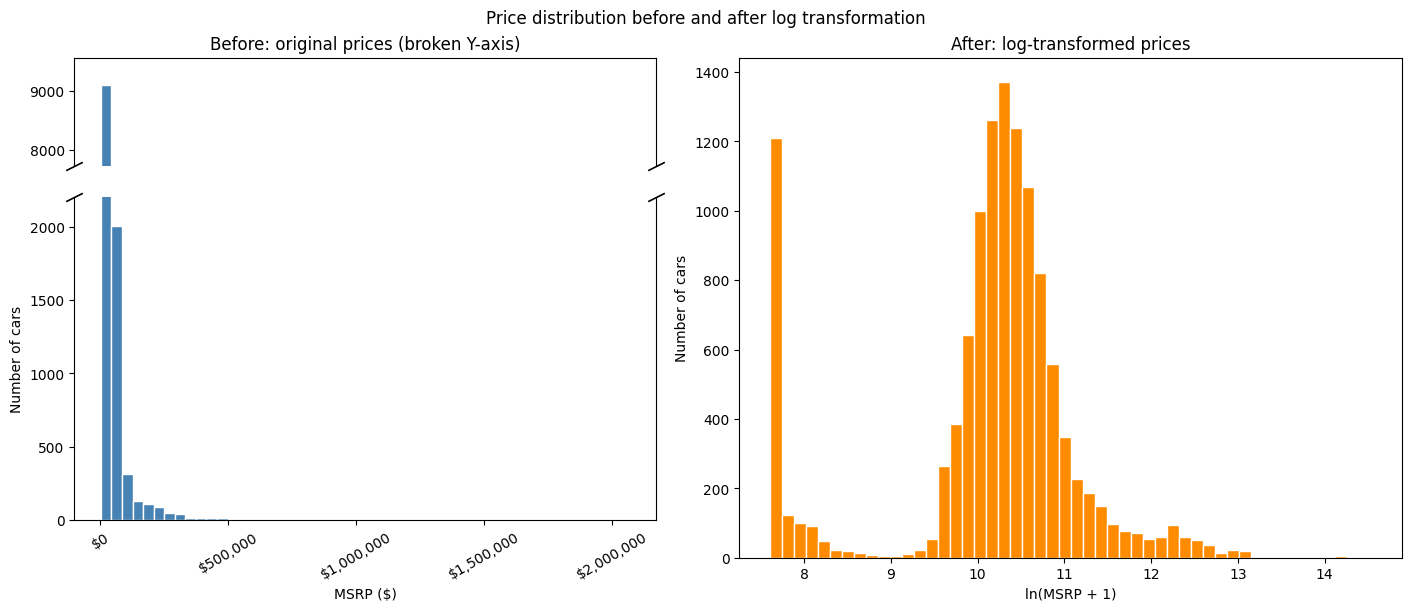

In [34]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Read original prices so rerunning this plot does not transform y again.
prices_for_plot = data['MSRP'].dropna()
log_prices_for_plot = np.log1p(prices_for_plot)
counts, price_bins = np.histogram(prices_for_plot, bins=50)

# Omit the middle of the count axis, keeping small counts and the tallest bar.
break_start = 2200
peak_count = counts.max()
use_axis_break = peak_count > break_start * 1.5

fig = plt.figure(figsize=(14, 6), layout='constrained')
panels = fig.add_gridspec(1, 2)

if use_axis_break:
    left_panels = panels[0].subgridspec(2, 1, height_ratios=[1, 3], hspace=0.05)
    ax_top = fig.add_subplot(left_panels[0])
    ax_bottom = fig.add_subplot(left_panels[1], sharex=ax_top)

    for ax in (ax_top, ax_bottom):
        ax.hist(prices_for_plot, bins=price_bins, color='steelblue', edgecolor='white')

    ax_bottom.set_ylim(0, break_start)
    ax_bottom.set_yticks([0, 500, 1000, 1500, 2000])
    ax_top.set_ylim(max(break_start + 1, peak_count * 0.85), peak_count * 1.05)
    ax_top.spines['bottom'].set_visible(False)
    ax_bottom.spines['top'].set_visible(False)
    ax_top.tick_params(axis='x', which='both', bottom=False, labelbottom=False)

    # Diagonal marks on both sides indicate the omitted Y-axis interval.
    for ax, boundary in ((ax_top, 0), (ax_bottom, 1)):
        ax.plot(
            [0, 1], [boundary, boundary],
            transform=ax.transAxes,
            marker=[(-1, -0.5), (1, 0.5)], markersize=12,
            linestyle='none', color='black',
            markeredgewidth=1.2, clip_on=False,
        )
    ax_top.set_title('Before: original prices (broken Y-axis)')
else:
    ax_bottom = fig.add_subplot(panels[0])
    ax_bottom.hist(prices_for_plot, bins=price_bins, color='steelblue', edgecolor='white')
    ax_bottom.set_title('Before: original prices')

ax_bottom.set(xlabel='MSRP ($)', ylabel='Number of cars')
ax_bottom.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax_bottom.tick_params(axis='x', labelrotation=30)

ax_log = fig.add_subplot(panels[1])
ax_log.hist(log_prices_for_plot, bins=50, color='darkorange', edgecolor='white')
ax_log.set(
    title='After: log-transformed prices',
    xlabel='ln(MSRP + 1)', ylabel='Number of cars',
)

fig.suptitle('Price distribution before and after log transformation')
plt.show()

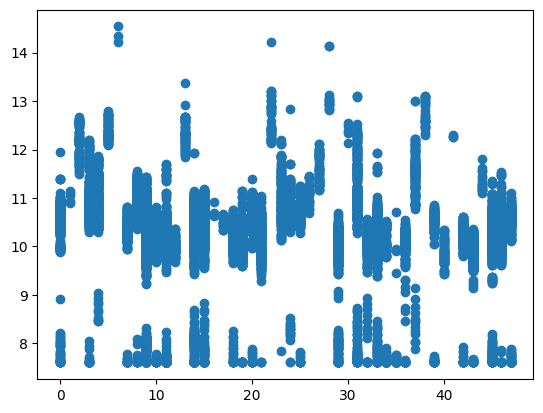

In [35]:
import matplotlib.pyplot as plt
%matplotlib inline
# This scatter plot shows car manufacturer versus log-transformed price, with one dot per car.
plt.scatter(x.Make,np.log(y+1))
y=np.log(y+1)

In [36]:
x.Year.min(),x.Year.max()

(1990, 2017)

In [37]:
# Improved output
x["Year"].agg(["min", "max"]).rename(
    index={"min": "Earliest year", "max": "Latest year"}
).to_frame(name="Year")

,Year
Earliest year,1990
Latest year,2017


In [38]:
# Improved output
print(f"Year range: {x['Year'].min()}–{x['Year'].max()}")

Year range: 1990–2017


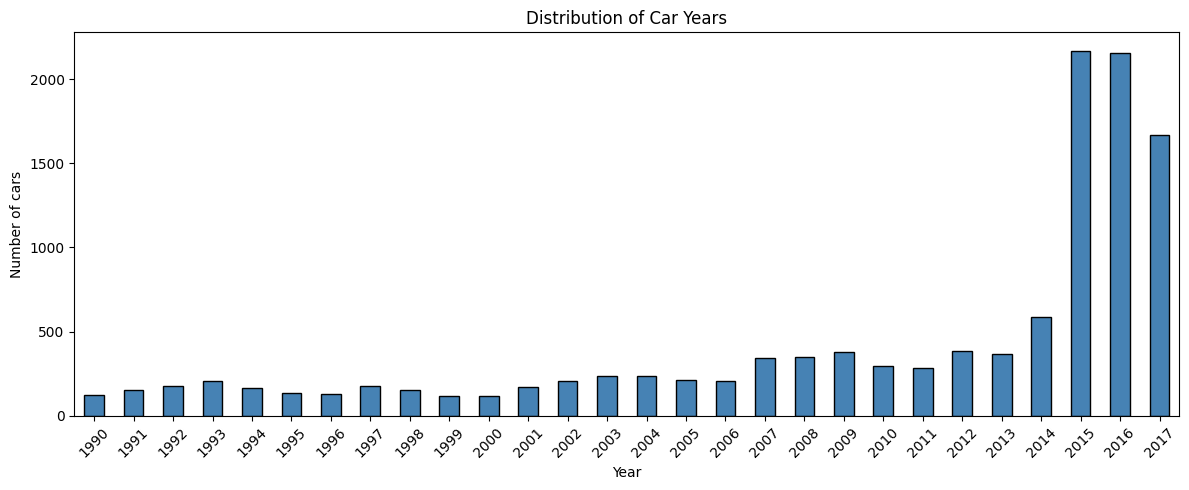

In [39]:
year_counts = x["Year"].value_counts().sort_index()

ax = year_counts.plot.bar(
    figsize=(12, 5),
    color="steelblue",
    edgecolor="black",
)

ax.set(
    title="Distribution of Car Years",
    xlabel="Year",
    ylabel="Number of cars",
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Grouping car years into five quantile bins

`x['Year'] = pd.qcut(x['Year'], 5, labels=False)` replaces each car's year with the number of its **quantile group**.

- `x['Year']` supplies the original years.
- `5` requests five groups using the 0th, 20th, 40th, 60th, 80th and 100th percentiles as boundaries. Each group aims to contain roughly 20% of the non-missing rows; the groups need not span the same number of years.
- `labels=False` returns integer codes: **0** for the oldest group through **4** for the newest group, rather than interval labels. The boundaries depend on the years in this dataset.
- Assigning the result back to `x['Year']` overwrites the actual years. To preserve them, use `x['Year_group'] = pd.qcut(x['Year'], 5, labels=False)` instead.

Grouping reduces the detail available to the model: years in the same bin receive the same code. Missing years remain missing. Repeated year values can make group sizes unequal; if quantile boundaries are duplicated, `qcut` raises an error. Adding `duplicates='drop'` permits fewer than five groups when that happens.

To inspect the boundaries before overwriting the years:

```python
year_groups, year_edges = pd.qcut(x['Year'], 5, labels=False, retbins=True)
print(year_edges)
```

Run this transformation on the original year values; rerunning it after overwriting `Year` would bin the group codes instead.

**Note:** we verified before that this column had no missing data.

In [40]:
x.iloc[rows_of_interest, 2]

473    2015
474    2015
475    2015
476    2015
477    2016
478    2016
Name: Year, dtype: int64

In [41]:
x['Year'] = pd.qcut(x['Year'], 5, labels=False)

In [42]:
x.iloc[rows_of_interest, 2]

473    2
474    2
475    2
476    2
477    3
478    3
Name: Year, dtype: int64

In [43]:
category.append('Year')

In [44]:
x['Engine Fuel Type'].value_counts()

Engine Fuel Type
regular unleaded                                7175
premium unleaded (required)                     2009
premium unleaded (recommended)                  1523
flex-fuel (unleaded/E85)                         899
diesel                                           154
electric                                          66
flex-fuel (premium unleaded required/E85)         54
flex-fuel (premium unleaded recommended/E85)      26
flex-fuel (unleaded/natural gas)                   6
natural gas                                        2
Name: count, dtype: int64

In [45]:
category.append('Engine Fuel Type')

In [46]:
x.iloc[14:20, 3]

14    premium unleaded (required)
15    premium unleaded (required)
16    premium unleaded (required)
17               regular unleaded
18               regular unleaded
19               regular unleaded
Name: Engine Fuel Type, dtype: object

In [47]:
change_method_int = 2
if change_method_int == 0:
    print("Changing the fuel type using the original code")
    x.loc[x['Engine Fuel Type'] == 'regular unleaded', 'Engine Fuel Type'] = 'regular'
    x.loc[x['Engine Fuel Type'] == 'premium unleaded (required)', 'Engine Fuel Type'] = 'premium'
    x.loc[x['Engine Fuel Type'] == 'premium unleaded (recommended)', 'Engine Fuel Type'] = 'premium'
    x.loc[x['Engine Fuel Type'] == 'flex-fuel (unleaded/E85)', 'Engine Fuel Type'] = 'flex-fuel'
    x.loc[x['Engine Fuel Type'] == 'flex-fuel (premium unleaded required/E85)', 'Engine Fuel Type'] = 'flex-fuel'
    x.loc[x['Engine Fuel Type'] == 'flex-fuel (premium unleaded recommended/E85)', 'Engine Fuel Type'] = 'flex-fuel'
    x.loc[x['Engine Fuel Type'] == 'flex-fuel (unleaded/natural gas)', 'Engine Fuel Type'] = 'flex-fuel'
else:
    if change_method_int == 1:
        print("Changing the fuel type using a dictionary")
        fuel_mapping = {
            "regular unleaded": "regular",
            "premium unleaded (required)": "premium",
            "premium unleaded (recommended)": "premium",
            "flex-fuel (unleaded/E85)": "flex-fuel",
            "flex-fuel (premium unleaded required/E85)": "flex-fuel",
            "flex-fuel (premium unleaded recommended/E85)": "flex-fuel",
            "flex-fuel (unleaded/natural gas)": "flex-fuel",
        }

        x["Engine Fuel Type"] = x["Engine Fuel Type"].replace(fuel_mapping)
    else:
        print("Changing the fuel type using a function and apply")
        def simplify_fuel_type(value):
            if not isinstance(value, str):
                return value  # Preserve missing values

            text = value.lower()

            for fuel_type in ["flex-fuel", "regular", "premium"]:
                if fuel_type in text:
                    return fuel_type

            return value  # Preserve other types, such as diesel


        x["Engine Fuel Type"] = x["Engine Fuel Type"].apply(simplify_fuel_type)

Changing the fuel type using a function and apply


In [48]:
x.iloc[14:20, 3]

14    premium
15    premium
16    premium
17    regular
18    regular
19    regular
Name: Engine Fuel Type, dtype: object

In [49]:
print("Sorted unique values")
display(x["Engine Fuel Type"].dropna().sort_values().unique())

Sorted unique values


array(['diesel', 'electric', 'flex-fuel', 'natural gas', 'premium',
       'regular'], dtype=object)

In [50]:
# Another option to display the unique values
set(x["Engine Fuel Type"])

{'diesel', 'electric', 'flex-fuel', 'natural gas', 'premium', 'regular'}

In [51]:
x['Engine Fuel Type'] = le.fit_transform(x['Engine Fuel Type'])

In [52]:
display(pd.DataFrame({
    "Fuel type": le.classes_,
    "Encoded value": range(len(le.classes_)),
}))

,Fuel type,Encoded value
0,diesel,0
1,electric,1
2,flex-fuel,2
3,natural gas,3
4,premium,4
5,regular,5


In [53]:
x.iloc[14:20, 3]

14    4
15    4
16    4
17    5
18    5
19    5
Name: Engine Fuel Type, dtype: int64

In [54]:
column_of_interest_number = x.columns.get_loc("Transmission Type")
x.iloc[14:20, column_of_interest_number]

14       MANUAL
15       MANUAL
16       MANUAL
17       MANUAL
18       MANUAL
19    AUTOMATIC
Name: Transmission Type, dtype: object

In [55]:
x['Transmission Type'] = le.fit_transform(x['Transmission Type'])
category.append('Transmission Type')

In [56]:
x.iloc[14:20, column_of_interest_number]

14    3
15    3
16    3
17    3
18    3
19    1
Name: Transmission Type, dtype: int64

In [57]:
column_of_interest_number = x.columns.get_loc("Driven_Wheels")
x.iloc[14:20, column_of_interest_number]

14     rear wheel drive
15     rear wheel drive
16     rear wheel drive
17    front wheel drive
18    front wheel drive
19      all wheel drive
Name: Driven_Wheels, dtype: object

In [58]:
x['Driven_Wheels'].value_counts()

Driven_Wheels
front wheel drive    4787
rear wheel drive     3371
all wheel drive      2353
four wheel drive     1403
Name: count, dtype: int64

In [59]:
x['Driven_Wheels'] = le.fit_transform(x['Driven_Wheels'])
category.append('Driven_Wheels')

In [60]:
x.iloc[14:20, column_of_interest_number]

14    3
15    3
16    3
17    2
18    2
19    0
Name: Driven_Wheels, dtype: int64

In [61]:
column_of_interest_number = x.columns.get_loc("Vehicle Size")
x.iloc[14:20, column_of_interest_number]

14    Compact
15    Compact
16    Compact
17    Midsize
18    Midsize
19    Midsize
Name: Vehicle Size, dtype: object

In [62]:
x['Vehicle Size'].value_counts()

Vehicle Size
Compact    4764
Midsize    4373
Large      2777
Name: count, dtype: int64

In [63]:
x['Vehicle Size'] = le.fit_transform(x['Vehicle Size'])
category.append('Vehicle Size')

In [64]:
x.iloc[14:20, column_of_interest_number]

14    0
15    0
16    0
17    2
18    2
19    2
Name: Vehicle Size, dtype: int64

In [65]:
column_of_interest_number = x.columns.get_loc("Vehicle Style")
x.iloc[14:20, column_of_interest_number]

14          Coupe
15    Convertible
16          Coupe
17          Sedan
18          Sedan
19          Wagon
Name: Vehicle Style, dtype: object

In [66]:
x['Vehicle Style'].value_counts()
x['Vehicle Style'] = le.fit_transform(x['Vehicle Style'])
category.append('Vehicle Style')

In [67]:
x.iloc[14:20, column_of_interest_number]

14     8
15     6
16     8
17    14
18    14
19    15
Name: Vehicle Style, dtype: int64

In [68]:
print(f"Columns where categorical variable is converted into dummy/indicator variables: {category}")

Columns where categorical variable is converted into dummy/indicator variables: ['Make', 'Model', 'Year', 'Engine Fuel Type', 'Transmission Type', 'Driven_Wheels', 'Vehicle Size', 'Vehicle Style']


In [69]:
x = pd.get_dummies(x, columns=category)

In [70]:
print_all_columns_bool = False
print_columns_by_type_bool = False

if print_all_columns_bool:
    for position, name in enumerate(x.columns):
        print(f"{position}: {name}")

if print_columns_by_type_bool:
    columns_by_type = {}

    for position, (name, dtype) in enumerate(x.dtypes.items()):
        columns_by_type.setdefault(str(dtype), []).append((position, name))

    for dtype, columns in columns_by_type.items():
        print(f"\n{dtype} ({len(columns)} columns)")

        if len(columns) <= 6:
            for position, name in columns:
                print(f"  {position}: {name}")
        else:
            for position, name in columns[:3]:
                print(f"  {position}: {name}")

            print("  ...")

            for position, name in columns[-3:]:
                print(f"  {position}: {name}")

# Print the first and last columns for each group.
column_groups = {}
columns_max_to_show = 4
assert columns_max_to_show > 0 and columns_max_to_show % 2 == 0, (
    "The number must be positive and even"
)
half = columns_max_to_show // 2

for position, name in enumerate(x.columns):
    group = name.rsplit("_", 1)[0] if "_" in name else name
    column_groups.setdefault(group, []).append((position, name))

for columns in column_groups.values():
    if len(columns) <= columns_max_to_show:
        for position, name in columns:
            print(f"{position}: {name}")
    else:
        for position, name in columns[:half]:
            print(f"{position}: {name}")

        print("    ...")

        for position, name in columns[-half:]:
            print(f"{position}: {name}")

0: Engine HP
1: Engine Cylinders
2: Number of Doors
3: highway MPG
4: city mpg
5: Popularity
6: Crossover
7: Diesel
8: Exotic
9: Factory Tuner
10: Flex Fuel
11: Hatchback
12: High-Performance
13: Hybrid
14: Luxury
15: Performance
16: Make_0
17: Make_1
    ...
62: Make_46
63: Make_47
64: Model_0
65: Model_1
    ...
977: Model_913
978: Model_914
979: Year_0
980: Year_1
    ...
982: Year_3
983: Year_4
984: Engine Fuel Type_0
985: Engine Fuel Type_1
    ...
988: Engine Fuel Type_4
989: Engine Fuel Type_5
990: Transmission Type_0
991: Transmission Type_1
    ...
993: Transmission Type_3
994: Transmission Type_4
995: Driven_Wheels_0
996: Driven_Wheels_1
997: Driven_Wheels_2
998: Driven_Wheels_3
999: Vehicle Size_0
1000: Vehicle Size_1
1001: Vehicle Size_2
1002: Vehicle Style_0
1003: Vehicle Style_1
    ...
1016: Vehicle Style_14
1017: Vehicle Style_15


In [71]:
for count in category:
     x=x.drop(count + '_0',axis=1)

In [72]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.33)

### DecisionTreeRegressor

A decision tree regressor predicts a **numeric target** by repeatedly splitting observations using feature thresholds. With the default squared-error criterion, each leaf predicts the mean training target of the observations reaching it.

In the next cell, `DecisionTreeRegressor()` creates the estimator; `dtr.fit(x_train, y_train)` learns its splits and leaf predictions. Afterwards, `dtr.predict(x_test)` produces predictions for unseen rows.

| Parameter | Default | Purpose |
|---|---|---|
| `criterion` | `'squared_error'` | Measures split quality through squared-error reduction. |
| `splitter` | `'best'` | Selects the best available split. |
| `max_depth` | `None` | No explicit depth cap. |
| `min_samples_split` | `2` | Minimum observations needed to split a node. |
| `min_samples_leaf` | `1` | Minimum observations in each leaf. |
| `max_features` | `None` | Considers all features at each split. |
| `random_state` | `None` | Set an integer for reproducible fitting. |
| `ccp_alpha` | `0.0` | Increasing this enables stronger cost-complexity pruning. |

Defaults allow large, unpruned trees. Tune depth, leaf size or pruning with validation to control overfitting.

**Notebook context:** if `y_train` contains `ln(MSRP + 1)`, predictions are also on that scale. Use `np.expm1(y_pred)` to return to price units.

**Output note:** the author does not use a predefine seed. Therefore, the results will vary on each execution. The paremeters used by the author are:

`DecisionTreeRegressor(criterion='mse', max_depth=None, max_features=None,
           max_leaf_nodes=None, min_impurity_decrease=0.0,
           min_impurity_split=None, min_samples_leaf=1,
           min_samples_split=2, min_weight_fraction_leaf=0.0,
           presort=False, random_state=None, splitter='best')`

However, 'mse' was deprecated in scikit-learn 1.0 and removed in 1.2, so on a current version it raises this error instead of a warning. It was only renamed, so the behaviour is the same:

| Old name | Current name |
|---|---|
| 'mse' | 'squared_error' |
| 'mae' | 'absolute_error' |

'squared_error' is also the default, so either of these works in the cell below.

Source:
- [scikit-learn — DecisionTreeRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html).
- [Manual of Decision Trees](https://scikit-learn.org/stable/modules/tree.html#tree)

In [73]:
from sklearn.tree import DecisionTreeRegressor
dtr= DecisionTreeRegressor(criterion='squared_error')
dtr.fit(x_train,y_train)

display_estimator(dtr)

DecisionTreeRegressor()

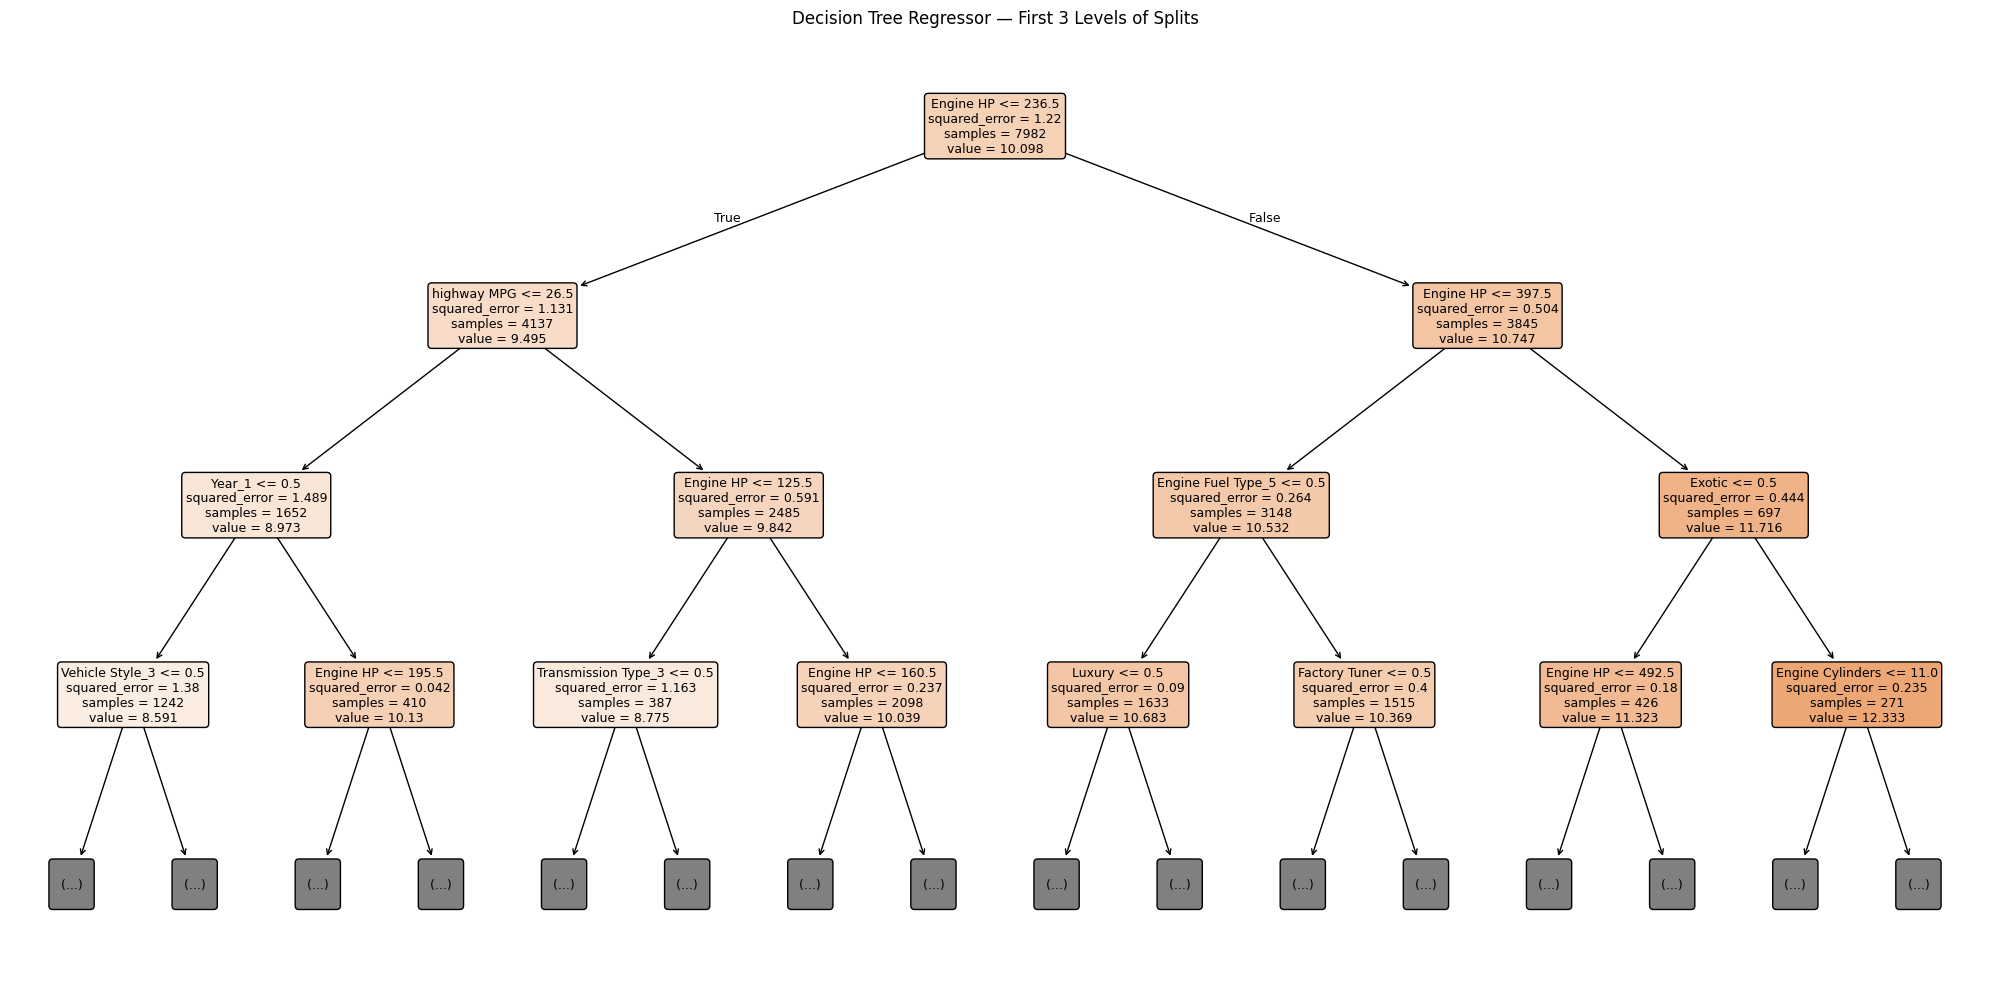

In [74]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    dtr,
    feature_names=x_train.columns.tolist(),
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("Decision Tree Regressor — First 3 Levels of Splits")
plt.tight_layout()
plt.show()

In [75]:
y_pred = dtr.predict(x_test)

In [76]:
from sklearn.metrics import mean_squared_error 
#mean_squared_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

display(pd.DataFrame({
    "Metric": ["MSE", "RMSE"],
    "Value": [mse, np.sqrt(mse)],
}).round(4))

,Metric,Value
0,MSE,0.0489
1,RMSE,0.2212


In [77]:
y_pred_train = dtr.predict(x_train)

In [78]:
#mean_squared_error(y_train, y_pred_train)

mse = mean_squared_error(y_train, y_pred_train)

display(pd.DataFrame({
    "Metric": ["MSE", "RMSE"],
    "Value": [mse, np.sqrt(mse)],
}).round(4))

,Metric,Value
0,MSE,0.0085
1,RMSE,0.0921


### Comparing linear regression and Ridge

Fit a `LinearRegression` baseline (`lr`) and two Ridge models on the same training data. The original example omitted creating and fitting `lr`; the cell below includes both steps.

The printed `.score()` values are **R²**, not accuracy: 1 is perfect, 0 matches a constant prediction of the evaluated target's mean, and negative values are worse. Ridge's `alpha` controls regularization strength; a larger value penalizes large coefficients more strongly, but does not guarantee better test performance. The `alpha` argument in `plt.plot()` controls marker transparency instead.

This comparison uses the existing features without standardization. Ridge penalties depend on feature scale, so consider scaling using training data when tuning regularization. Scores refer to the target scale used in `y_train` and `y_test`.

**Addendum — missing values:** `Ridge` does not accept missing values encoded as `NaN` natively. `LinearRegression` has the same limitation. In this dataset, `Engine HP`, `Engine Cylinders` and `Number of Doors` contain missing values, so they must be handled before fitting these models.

The code below uses `SimpleImputer(strategy='median', keep_empty_features=True)`. It learns each column's median from `x_train` with `fit_transform()`, then applies those same replacement values to `x_test` with `transform()`. This avoids using test data to calculate the replacements. Non-missing values remain unchanged, and all three models use the same imputed features. With `keep_empty_features=True`, a column that is entirely missing during fitting is retained and filled with 0.

,Train NaNs,Test NaNs,Replacement,Method
Engine HP,50,19,225.0,Training median
Engine Cylinders,21,9,6.0,Training median
Number of Doors,4,2,4.0,Training median


Model,Train R²,Test R²,Nonzero coefficients
Linear Regression,0.9795,"-286,978,349,968.7825",1008
Ridge (alpha=0.01),0.9794,0.9593,979
Ridge (alpha=100),0.8129,0.8178,979


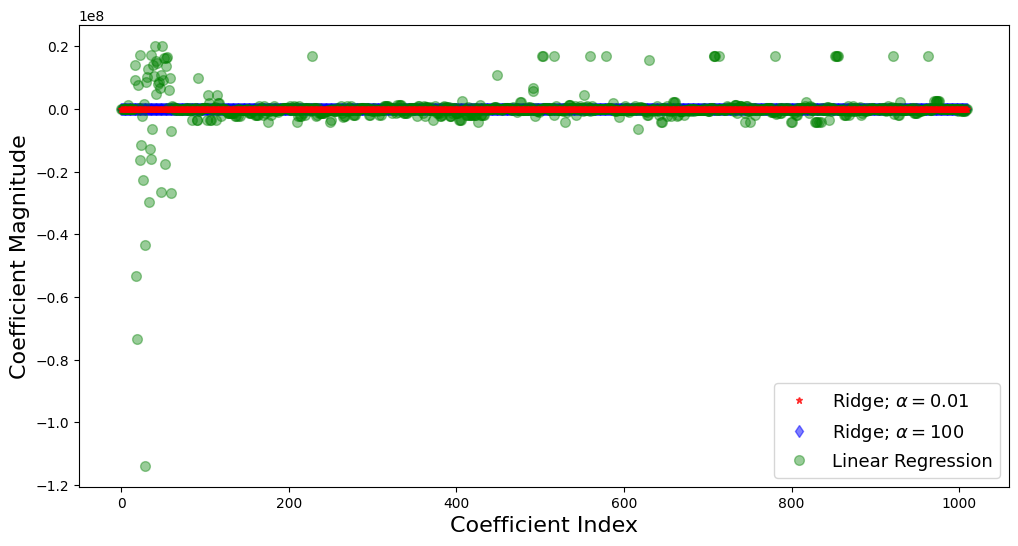

In [79]:
from sklearn.linear_model import Ridge
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
'''
UNUSED IMPORTS REMOVED
from sklearn.datasets import load_boston
from sklearn.model_selection import train_test_split
# Incorrect: from sklearn.cross_validation import train_test_split
'''

missing = pd.DataFrame({
    "Train NaNs": x_train.isna().sum(),
    "Test NaNs": x_test.isna().sum(),
})
needs_imputation = missing.any(axis=1)

if needs_imputation.any():
    # Learn replacement values from training data only.
    ridge_imputer = SimpleImputer(
        strategy="median",
        keep_empty_features=True,
    ).set_output(transform="pandas")

    x_train_imputed = ridge_imputer.fit_transform(x_train)
    x_test_imputed = ridge_imputer.transform(x_test)

    report = missing.loc[needs_imputation].copy()
    report["Replacement"] = pd.Series(
        ridge_imputer.statistics_,
        index=x_train.columns,
    )
    report["Method"] = [
        "0 (training column entirely missing)"
        if x_train[column].isna().all()
        else "Training median"
        for column in report.index
    ]

    display(report)
else:
    x_train_imputed = x_train
    x_test_imputed = x_test
    print("No missing values; no imputation needed.")

lr = LinearRegression()
lr.fit(x_train_imputed, y_train)

# Larger alpha strengthens regularization; validation determines which generalizes best.
# Original comment: # higher the alpha value, more restriction on the coefficients; low alpha > more generalization, coefficients are barely
# restricted and in this case linear and ridge regression resembles
rr = Ridge(alpha=0.01)
# Changed from x_train to x_train_imputed in the lines below
rr.fit(x_train_imputed, y_train)
rr100 = Ridge(alpha=100) #  comparison with alpha value
rr100.fit(x_train_imputed, y_train)
train_score=lr.score(x_train_imputed, y_train)
test_score=lr.score(x_test_imputed, y_test)
Ridge_train_score = rr.score(x_train_imputed,y_train)
Ridge_test_score = rr.score(x_test_imputed, y_test)
Ridge_train_score100 = rr100.score(x_train_imputed,y_train)
Ridge_test_score100 = rr100.score(x_test_imputed, y_test)

'''
print ("linear regression train score:", train_score)
print ("linear regression test score:", test_score)
print ("ridge regression train score low alpha:", Ridge_train_score)
print ("ridge regression test score low alpha:", Ridge_test_score)
print ("ridge regression train score high alpha:", Ridge_train_score100)
print ("ridge regression test score high alpha:", Ridge_test_score100)
'''

scores = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge (alpha=0.01)",
        "Ridge (alpha=100)",
    ],
    "Train R²": [
        train_score,
        Ridge_train_score,
        Ridge_train_score100,
    ],
    "Test R²": [
        test_score,
        Ridge_test_score,
        Ridge_test_score100,
    ],
}).set_index("Model")

'''display(scores.round(4))

display(scores.style.format({
    "Train R²": "{:.4f}",
    "Test R²": "{:,.4f}",
}))'''

scores["Nonzero coefficients"] = [
    np.count_nonzero(lr.coef_),
    np.count_nonzero(rr.coef_),
    np.count_nonzero(rr100.coef_),
]

display_table(
    scores.reset_index(),
    formats={
        "Train R²": "{:.4f}",
        "Test R²": "{:,.4f}",
        "Nonzero coefficients": "{:d}",
    },
    hide_index=True,
)

plt.figure(figsize=(12, 6))
plt.plot(rr.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Ridge; $\alpha = 0.01$',zorder=7) # zorder for ordering the markers
plt.plot(rr100.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Ridge; $\alpha = 100$') # alpha here is for transparency
plt.plot(lr.coef_,alpha=0.4,linestyle='none',marker='o',markersize=7,color='green',label='Linear Regression')
plt.xlabel('Coefficient Index',fontsize=16)
plt.ylabel('Coefficient Magnitude',fontsize=16)
plt.legend(fontsize=13,loc=4)
plt.show()

### Comparing Lasso and linear regression

**Lasso** is linear regression with an **L1 penalty** on the coefficients: the training objective combines prediction error with `alpha` times the sum of the absolute coefficient values. This penalty can shrink coefficients to exactly zero, allowing Lasso to select features as part of fitting.

The next cell compares three Lasso models with a `LinearRegression` baseline, using the same imputed training and test features:

| Model | Regularization strength |
|---|---|
| `Lasso()` | Default `alpha=1`: strongest penalty among these three models. |
| `Lasso(alpha=0.01)` | Smaller penalty, allowing more flexibility. |
| `Lasso(alpha=0.0001)` | Weakest penalty among these models. |
| `LinearRegression()` | No regularization penalty. |

A larger `alpha` generally produces more shrinkage and fewer nonzero coefficients. A smaller value allows a closer fit to training data, but does not guarantee better performance on unseen data.

**Reading the results**

- `.fit(x_train_imputed, y_train)` learns each model's coefficients.
- `.score(...)` reports **R²**: 1 is perfect, 0 matches predicting the evaluated target's mean, and negative values indicate worse performance than that baseline. Comparing training and test scores helps assess generalization.
- `np.sum(model.coef_ != 0)` counts nonzero coefficients. These correspond to retained input columns, including individual encoded categories, rather than necessarily distinct original features.
- `max_iter=1_000_000` sets the maximum number of optimization iterations. It must be an integer. It is a cap, not the number necessarily used, and does not itself guarantee convergence.

**Reading the plots**

The horizontal axis is the feature's position in the input columns; the vertical axis is its fitted coefficient. A zero coefficient means that feature contributes nothing to that model's prediction. Each marker style represents a model. The `alpha` in `plt.plot()` controls transparency and is unrelated to Lasso's regularization parameter. The model named `lasso00001` actually uses `alpha=0.0001`; interpret it using its constructor value.

**Preprocessing and interpretation**

Lasso and linear regression require missing values to be handled first. This block reuses the features imputed in the preceding comparison, where replacement values were learned from training data only. The features are not standardized here: because the penalty depends on coefficient magnitude, feature scale affects Lasso's results. Fit any scaler on training data only, and select `alpha` using validation or cross-validation rather than repeatedly tuning against the test set. If the target is log-transformed price, scores and coefficients describe that transformed target.

Source: [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html)

Model,Train R²,Test R²,Nonzero coefficients
Lasso (alpha=1),0.4981,0.5203,3
Lasso (alpha=0.01),0.7653,0.7815,23
Lasso (alpha=0.0001),0.9599,0.9416,582
Linear Regression,0.9795,"-286,978,349,968.7825",1008


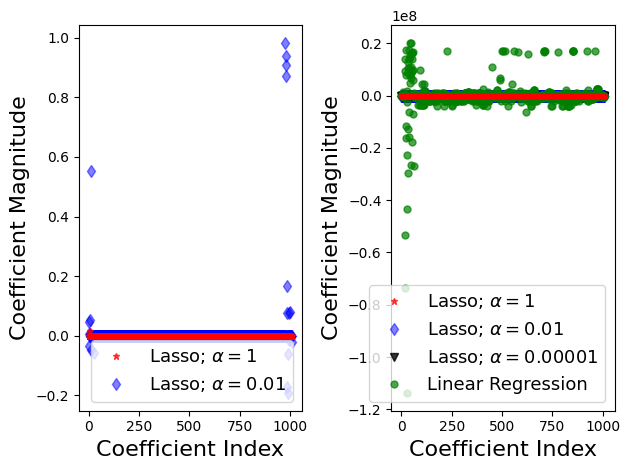

In [80]:
from sklearn.linear_model import Lasso
lasso = Lasso(alpha=1.0) # Lasso also requires removing the NaNs

lasso.fit(x_train_imputed,y_train)
train_score=lasso.score(x_train_imputed,y_train)
test_score=lasso.score(x_test_imputed,y_test)
coeff_used = np.sum(lasso.coef_!=0)
'''print ("training score:", train_score )
print ("test score: ", test_score)
print ("number of features used: ", coeff_used)'''
lasso001 = Lasso(alpha=0.01, max_iter=1_000_000) # Incorrect: lasso001 = Lasso(alpha=0.01, max_iter=10e5)
lasso001.fit(x_train_imputed,y_train)
train_score001=lasso001.score(x_train_imputed,y_train)
test_score001=lasso001.score(x_test_imputed,y_test)
coeff_used001 = np.sum(lasso001.coef_!=0)
'''print ("training score for alpha=0.01:", train_score001 )
print ("test score for alpha =0.01: ", test_score001)
print ("number of features used: for alpha =0.01:", coeff_used001)'''
lasso00001 = Lasso(alpha=0.0001, max_iter=1_000_000) # Incorrect: lasso00001 = Lasso(alpha=0.0001, max_iter=10e5)
lasso00001.fit(x_train_imputed,y_train)
train_score00001=lasso00001.score(x_train_imputed,y_train)
test_score00001=lasso00001.score(x_test_imputed,y_test)
coeff_used00001 = np.sum(lasso00001.coef_!=0)
'''print ("training score for alpha=0.0001:", train_score00001 )
print ("test score for alpha =0.0001: ", test_score00001)
print ("number of features used: for alpha =0.0001:", coeff_used00001)'''
lr = LinearRegression()
lr.fit(x_train_imputed,y_train)
lr_train_score=lr.score(x_train_imputed,y_train)
lr_test_score=lr.score(x_test_imputed,y_test)
'''print ("LR training score:", lr_train_score )
print ("LR test score: ", lr_test_score)'''

results = pd.DataFrame({
    "Model": [
        "Lasso (alpha=1)",
        "Lasso (alpha=0.01)",
        "Lasso (alpha=0.0001)",
        "Linear Regression",
    ],
    "Train R²": [
        train_score,
        train_score001,
        train_score00001,
        lr_train_score,
    ],
    "Test R²": [
        test_score,
        test_score001,
        test_score00001,
        lr_test_score,
    ],
    "Nonzero coefficients": [
        coeff_used,
        coeff_used001,
        coeff_used00001,
        np.count_nonzero(lr.coef_),
    ],
}).set_index("Model")

'''display(results.round(4))

display(results.style.format({
    "Train R²": "{:.4f}",
    "Test R²": "{:,.4f}",
    "Nonzero coefficients": "{:d}",
}))'''

display_table(
    results.reset_index(),
    formats={
        "Train R²": "{:.4f}",
        "Test R²": "{:,.4f}",
        "Nonzero coefficients": "{:d}",
    },
    hide_index=True,
)

plt.subplot(1,2,1)
plt.plot(lasso.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Lasso; $\alpha = 1$',zorder=7) # alpha here is for transparency
plt.plot(lasso001.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Lasso; $\alpha = 0.01$') # alpha here is for transparency

plt.xlabel('Coefficient Index',fontsize=16)
plt.ylabel('Coefficient Magnitude',fontsize=16)
plt.legend(fontsize=13,loc=4)
plt.subplot(1,2,2)
plt.plot(lasso.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Lasso; $\alpha = 1$',zorder=7) # alpha here is for transparency
plt.plot(lasso001.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Lasso; $\alpha = 0.01$') # alpha here is for transparency
plt.plot(lasso00001.coef_,alpha=0.8,linestyle='none',marker='v',markersize=6,color='black',label=r'Lasso; $\alpha = 0.00001$') # alpha here is for transparency
plt.plot(lr.coef_,alpha=0.7,linestyle='none',marker='o',markersize=5,color='green',label='Linear Regression',zorder=2)
plt.xlabel('Coefficient Index',fontsize=16)
plt.ylabel('Coefficient Magnitude',fontsize=16)
plt.legend(fontsize=13,loc=4)
plt.tight_layout()
plt.show()

### Conclusions from this model comparison

These conclusions describe the reported train/test split and preprocessing. The scores are **R² on the target scale used for training**; if the target is log-transformed MSRP, they measure performance on log prices, not dollar prices.

*Note that the values below come from a previous run of this notebook. As the `seed` is not fixed, each run will have different outputs.*

| Model | Train R² | Test R² | Nonzero coefficients reported |
|---|---:|---:|---:|
| Linear Regression | 0.9778 | −104,930,490,647.9024 | 1009 |
| Ridge (`alpha=0.01`) | 0.9776 | 0.9673 | 987 |
| Ridge (`alpha=100`) | 0.8165 | 0.7745 | 987 |
| Lasso (`alpha=1`) | 0.5128 | 0.5088 | 3 |
| Lasso (`alpha=0.01`) | 0.7699 | 0.7576 | 22 |
| Lasso (`alpha=0.0001`) | 0.9589 | 0.9440 | 573 |

**Ridge with `alpha=0.01` performed best on this test split.** Its test R² of 0.9673 is close to its training R² of 0.9776, suggesting good generalization on this split. A small regularization penalty preserved the strong training fit while avoiding the extreme test failure seen with ordinary Linear Regression.

**Linear Regression's training score is misleading when viewed alone.** Its enormous negative test R² means its squared prediction error is vastly larger than that of predicting the test target's mean. R² can be negative without a lower bound. This result calls for investigation of extreme predictions, redundant encoded columns, numerical conditioning and train/test feature consistency. The score alone does not establish the cause; the improvement with Ridge is consistent with regularization stabilizing the fit.

**Stronger regularization reduced performance in the tested settings.** Ridge at `alpha=100` has substantially lower training and test scores than Ridge at `alpha=0.01`. Lasso at `alpha=1` retains only three input columns and has low scores on both sets, suggesting underfitting relative to the weaker penalties tried here. A small train/test gap does not by itself imply a good model.

**Lasso offers a trade-off between predictive performance and sparsity.** Reducing its penalty increased the number of nonzero coefficients from 3 to 22 to 573 and improved test R² from 0.5088 to 0.7576 to 0.9440. Lasso at `alpha=0.0001` is the strongest Lasso candidate tested, but remains below Ridge at `alpha=0.01`. These counts refer to encoded input columns, not necessarily distinct original features. Nonzero coefficients do not establish causal importance, and tiny Linear Regression coefficients may still be counted as nonzero.

**Next steps:** treat Ridge at `alpha=0.01` as the leading candidate, not a universally optimal choice. Compare training-fitted imputation and scaling pipelines using cross-validation, tune penalties on validation folds, and reserve an untouched test set for final evaluation. Ridge and Lasso penalize coefficients differently, so equal `alpha` values are not directly comparable across them. Set a fixed `random_state` for a reproducible split, and investigate the Linear Regression failure. If predicting prices, also report MAE and RMSE in original price units after reversing the target transformation.

In [81]:
#Ridge Regression Low Alpha can be chosen